In [1]:

# ==========================================
# STORYGPT - AI STORY GENERATOR
# Stage 1: Environment Setup
# ==========================================

import os
import random
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

# Set random seeds for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Select available device
device = 'cuda' if torch.cuda.is_available() else 'cpu'

print("PyTorch Version:", torch.__version__)
print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")


PyTorch Version: 2.14.1+cu130
Selected Device: cuda
GPU: Tesla T4


In [2]:

# ==========================================
# STAGE 1: DOWNLOAD DATASET
# ==========================================

dataset_url = (
    "https://raw.githubusercontent.com/"
    "karpathy/char-rnn/master/data/"
    "tinyshakespeare/input.txt"
)

# Download dataset
urllib.request.urlretrieve(
    dataset_url,
    "input.txt"
)

# Read dataset
with open("input.txt", "r", encoding="utf-8") as file:
    text = file.read()

print("Dataset downloaded successfully!")
print("Total characters:", len(text))
print("\nFirst 1000 characters:\n")
print(text[:1000])


Dataset downloaded successfully!
Total characters: 1115394

First 1000 characters:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rak

In [3]:

# ==========================================
# STAGE 1: DATASET EXPLORATION
# ==========================================

print("Dataset Statistics")
print("-------------------")

print("Total Characters:", len(text))

# Find all unique characters
unique_characters = sorted(list(set(text)))

print("Unique Characters:", len(unique_characters))

print("\nCharacter Vocabulary:")
print(unique_characters)

# Dataset size in KB
print(
    "\nDataset Size:",
    round(len(text.encode("utf-8")) / 1024, 2),
    "KB"
)


Dataset Statistics
-------------------
Total Characters: 1115394
Unique Characters: 65

Character Vocabulary:
['\n', ' ', '!', '$', '&', "'", ',', '-', '.', '3', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']

Dataset Size: 1089.25 KB


In [4]:

# ==========================================
# STAGE 2: BUILD CHARACTER VOCABULARY
# ==========================================

# Get all unique characters and sort them
chars = sorted(list(set(text)))

# Total number of unique characters
vocab_size = len(chars)

print("Vocabulary Size:", vocab_size)

# Display vocabulary
print("Vocabulary:", ''.join(chars))


Vocabulary Size: 65
Vocabulary: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz


In [5]:

# ==========================================
# STAGE 2: CHARACTER TO INTEGER MAPPING
# ==========================================

# Create character-to-integer dictionary
stoi = {ch: i for i, ch in enumerate(chars)}

# Create integer-to-character dictionary
itos = {i: ch for i, ch in enumerate(chars)}

# Display first 15 mappings
print("Character to Integer Mapping:")

for ch, i in list(stoi.items())[:15]:
    print(repr(ch), ":", i)


Character to Integer Mapping:
'\n' : 0
' ' : 1
'!' : 2
'$' : 3
'&' : 4
"'" : 5
',' : 6
'-' : 7
'.' : 8
'3' : 9
':' : 10
';' : 11
'?' : 12
'A' : 13
'B' : 14


In [6]:

# ==========================================
# STAGE 2: CUSTOM TOKENIZER
# ==========================================

# Encode: Convert text into numerical tokens
def encode(input_text):
    return [stoi[ch] for ch in input_text]


# Decode: Convert numerical tokens back into text
def decode(token_ids):
    return ''.join([itos[i] for i in token_ids])


# Test our tokenizer
sample_text = "Hello world!"

encoded_text = encode(sample_text)

decoded_text = decode(encoded_text)

print("Original Text:", sample_text)

print("Encoded Text:", encoded_text)

print("Decoded Text:", decoded_text)


Original Text: Hello world!
Encoded Text: [20, 43, 50, 50, 53, 1, 61, 53, 56, 50, 42, 2]
Decoded Text: Hello world!


In [7]:

# ==========================================
# STAGE 2: TOKENIZER VALIDATION
# ==========================================

test_text = "The king is powerful."

# Convert text into numbers
encoded = encode(test_text)

# Convert numbers back into text
decoded = decode(encoded)

# Check whether both texts match
print("Original:", test_text)
print("Decoded:", decoded)

if test_text == decoded:
    print("\nTokenizer working correctly!")
else:
    print("\nTokenizer error!")

# Additional validation
assert decoded == test_text
assert len(encoded) == len(test_text)

print("All tokenizer tests passed!")


Original: The king is powerful.
Decoded: The king is powerful.

Tokenizer working correctly!
All tokenizer tests passed!


In [8]:

# ==========================================
# STAGE 3: CONVERT DATASET INTO NUMBERS
# ==========================================

# Encode the complete dataset
data = torch.tensor(encode(text), dtype=torch.long)

print("Dataset converted into numerical tokens!")

print("Total tokens:", len(data))

print("\nFirst 100 tokens:")
print(data[:100])

print("\nTensor shape:", data.shape)


Dataset converted into numerical tokens!
Total tokens: 1115394

First 100 tokens:
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59])

Tensor shape: torch.Size([1115394])


In [9]:

# ==========================================
# STAGE 3: TRAIN-VALIDATION SPLIT
# ==========================================

# Calculate the splitting position
split_index = int(0.90 * len(data))

# First 90% for training
train_data = data[:split_index]

# Remaining 10% for validation
val_data = data[split_index:]

print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))

print("\nTraining percentage:",
      round(len(train_data) / len(data) * 100, 2), "%")

print("Validation percentage:",
      round(len(val_data) / len(data) * 100, 2), "%")


Training tokens: 1003854
Validation tokens: 111540

Training percentage: 90.0 %
Validation percentage: 10.0 %


In [10]:

# ==========================================
# STAGE 3: TRAINING CONFIGURATION
# ==========================================

# Number of sequences processed together
batch_size = 64

# Maximum previous characters the model can see
block_size = 128

# Total number of unique characters
vocab_size = len(chars)

print("Batch Size:", batch_size)
print("Context Length:", block_size)
print("Vocabulary Size:", vocab_size)


Batch Size: 64
Context Length: 128
Vocabulary Size: 65


In [11]:

# ==========================================
# STAGE 3: GENERATE TRAINING BATCHES
# ==========================================

def get_batch(split):

    # Select training or validation dataset
    data_source = train_data if split == 'train' else val_data

    # Randomly select starting positions
    ix = torch.randint(
        len(data_source) - block_size - 1,
        (batch_size,)
    )

    # Create input sequences
    x = torch.stack([
        data_source[i:i + block_size]
        for i in ix
    ])

    # Create target sequences (shifted by one)
    y = torch.stack([
        data_source[i + 1:i + block_size + 1]
        for i in ix
    ])

    # Move tensors to GPU or CPU
    x = x.to(device)
    y = y.to(device)

    return x, y


In [12]:

# ==========================================
# STAGE 3: TEST BATCH GENERATION
# ==========================================

# Generate one training batch
xb, yb = get_batch('train')

print("Input batch shape:", xb.shape)
print("Target batch shape:", yb.shape)

# Display one example
print("\nFirst input sequence:")
print(decode(xb[0].tolist()))

print("\nCorresponding target sequence:")
print(decode(yb[0].tolist()))

# Check that target is shifted by one position
assert torch.equal(xb[:, 1:], yb[:, :-1])

print("\nBatch generation working correctly!")


Input batch shape: torch.Size([64, 128])
Target batch shape: torch.Size([64, 128])

First input sequence:
 passage.

Second Watchman:
Ay, wherefore else guard we his royal tent,
But to defend his person from night-foes?

WARWICK:
This

Corresponding target sequence:
passage.

Second Watchman:
Ay, wherefore else guard we his royal tent,
But to defend his person from night-foes?

WARWICK:
This 

Batch generation working correctly!


In [13]:
# Number of numerical values used to represent each character
n_embd = 128

# Number of attention heads
n_head = 4

# Number of Transformer blocks
n_layer = 4

# Dropout helps reduce overfitting
dropout = 0.1

print("Embedding dimension:", n_embd)
print("Attention heads:", n_head)
print("Transformer layers:", n_layer)
print("Dropout:", dropout)

Embedding dimension: 128
Attention heads: 4
Transformer layers: 4
Dropout: 0.1


In [14]:
# Convert character IDs into learnable vectors
token_embedding_table = nn.Embedding(
    vocab_size,
    n_embd
)

# Learn the position of each character
position_embedding_table = nn.Embedding(
    block_size,
    n_embd
)

# Move embedding layers to GPU
token_embedding_table = token_embedding_table.to(device)
position_embedding_table = position_embedding_table.to(device)

print("Token embedding layer created!")
print("Position embedding layer created!")

Token embedding layer created!
Position embedding layer created!


In [15]:
# Get a sample batch
xb, yb = get_batch('train')

# Get batch size and sequence length
B, T = xb.shape

# Convert input characters into vectors
token_embeddings = token_embedding_table(xb)

# Create position numbers: 0, 1, 2, ... 127
positions = torch.arange(T, device=device)

# Convert positions into vectors
position_embeddings = position_embedding_table(positions)

# Combine character information and position information
x = token_embeddings + position_embeddings

print("Input shape:", xb.shape)
print("Token embedding shape:", token_embeddings.shape)
print("Position embedding shape:", position_embeddings.shape)
print("Combined embedding shape:", x.shape)

Input shape: torch.Size([64, 128])
Token embedding shape: torch.Size([64, 128, 128])
Position embedding shape: torch.Size([128, 128])
Combined embedding shape: torch.Size([64, 128, 128])


In [16]:
class Head(nn.Module):

    def __init__(self, head_size):
        super().__init__()

        # Convert input embeddings into Query, Key and Value
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        # Create a lower triangular causal mask
        self.register_buffer(
            'tril',
            torch.tril(torch.ones(block_size, block_size))
        )

        # Dropout layer
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        B, T, C = x.shape

        # Calculate Query, Key and Value
        k = self.key(x)
        q = self.query(x)
        v = self.value(x)

        # Calculate attention scores
        weights = q @ k.transpose(-2, -1)

        # Scale attention scores
        weights = weights * (k.shape[-1] ** -0.5)

        # Apply causal mask
        weights = weights.masked_fill(
            self.tril[:T, :T] == 0,
            float('-inf')
        )

        # Convert scores into probabilities
        weights = F.softmax(weights, dim=-1)

        # Apply dropout
        weights = self.dropout(weights)

        # Combine information using attention weights
        out = weights @ v

        return out

In [17]:
# Get a sample batch
xb, yb = get_batch('train')

# Create one attention head
head_size = 32

head = Head(head_size).to(device)

# Get embeddings
token_embeddings = token_embedding_table(xb)

positions = torch.arange(block_size, device=device)

position_embeddings = position_embedding_table(positions)

x = token_embeddings + position_embeddings

# Pass embeddings through self-attention
output = head(x)

print("Input shape:", x.shape)
print("Attention output shape:", output.shape)
print("\nSelf-attention head working correctly!")

Input shape: torch.Size([64, 128, 128])
Attention output shape: torch.Size([64, 128, 32])

Self-attention head working correctly!


In [18]:
class MultiHeadAttention(nn.Module):

    def __init__(self, num_heads, head_size):
        super().__init__()

        # Create multiple independent attention heads
        self.heads = nn.ModuleList([
            Head(head_size)
            for _ in range(num_heads)
        ])

        # Dropout for regularization
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        # Run all attention heads on the same input
        outputs = [head(x) for head in self.heads]

        # Concatenate their outputs
        out = torch.cat(outputs, dim=-1)

        # Apply dropout
        out = self.dropout(out)

        return out

In [19]:
head_size = n_embd // n_head

multi_head = MultiHeadAttention(
    num_heads=n_head,
    head_size=head_size
).to(device)

# Test using the combined embeddings from earlier
output = multi_head(x)

print("Input shape:", x.shape)
print("Multi-head attention output shape:", output.shape)

assert output.shape == (batch_size, block_size, n_embd)

print("\nMulti-Head Attention working correctly!")

Input shape: torch.Size([64, 128, 128])
Multi-head attention output shape: torch.Size([64, 128, 128])

Multi-Head Attention working correctly!


In [20]:
class FeedForward(nn.Module):

    def __init__(self, n_embd):
        super().__init__()

        self.network = nn.Sequential(

            # Expand dimensions: 128 -> 512
            nn.Linear(n_embd, 4 * n_embd),

            # Apply non-linearity
            nn.ReLU(),

            # Reduce dimensions: 512 -> 128
            nn.Linear(4 * n_embd, n_embd),

            # Apply dropout
            nn.Dropout(dropout)
        )

    def forward(self, x):

        return self.network(x)

In [21]:
# Create Feed-Forward Network
ffn = FeedForward(n_embd).to(device)

# Pass multi-head attention output through FFN
ffn_output = ffn(output)

print("Input shape:", output.shape)
print("Feed-Forward output shape:", ffn_output.shape)

assert ffn_output.shape == output.shape

print("\nFeed-Forward Network working correctly!")

Input shape: torch.Size([64, 128, 128])
Feed-Forward output shape: torch.Size([64, 128, 128])

Feed-Forward Network working correctly!


In [22]:
class Block(nn.Module):

    def __init__(self, n_embd, n_head):
        super().__init__()

        # Calculate dimension of each attention head
        head_size = n_embd // n_head

        # Multi-Head Self-Attention
        self.sa = MultiHeadAttention(n_head, head_size)

        # Feed-Forward Network
        self.ffwd = FeedForward(n_embd)

        # Layer Normalization
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):

        # Attention + residual connection
        x = x + self.sa(self.ln1(x))

        # Feed-Forward + residual connection
        x = x + self.ffwd(self.ln2(x))

        return x

In [23]:
# Create one Transformer Block
block = Block(n_embd, n_head).to(device)

# Pass embeddings through the block
block_output = block(x)

print("Input shape:", x.shape)
print("Transformer Block output shape:", block_output.shape)

assert block_output.shape == x.shape

print("\nTransformer Block working correctly!")

Input shape: torch.Size([64, 128, 128])
Transformer Block output shape: torch.Size([64, 128, 128])

Transformer Block working correctly!


In [24]:
class GPTLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()

        # Token embedding
        self.token_embedding_table = nn.Embedding(
            vocab_size, n_embd
        )

        # Positional embedding
        self.position_embedding_table = nn.Embedding(
            block_size, n_embd
        )

        # Stack four Transformer Blocks
        self.blocks = nn.Sequential(
            *[Block(n_embd, n_head) for _ in range(n_layer)]
        )

        # Final Layer Normalization
        self.ln_f = nn.LayerNorm(n_embd)

        # Convert embeddings into vocabulary scores
        self.lm_head = nn.Linear(n_embd, vocab_size)

        # Initialize model weights randomly
        self.apply(self._init_weights)

    def _init_weights(self, module):

        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(
                module.weight, mean=0.0, std=0.02
            )

            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)

        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(
                module.weight, mean=0.0, std=0.02
            )

    def forward(self, idx, targets=None):

        B, T = idx.shape

        # Token embeddings
        tok_emb = self.token_embedding_table(idx)

        # Positional embeddings
        pos = torch.arange(T, device=device)
        pos_emb = self.position_embedding_table(pos)

        # Combine token and position information
        x = tok_emb + pos_emb

        # Pass through Transformer Blocks
        x = self.blocks(x)

        # Final normalization
        x = self.ln_f(x)

        # Generate vocabulary logits
        logits = self.lm_head(x)

        loss = None

        if targets is not None:

            B, T, C = logits.shape

            logits = logits.view(B * T, C)
            targets = targets.view(B * T)

            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):

        for _ in range(max_new_tokens):

            # Keep only the last block_size characters
            idx_cond = idx[:, -block_size:]

            # Get predictions
            logits, loss = self(idx_cond)

            # Select predictions for the last position
            logits = logits[:, -1, :]

            # Convert scores into probabilities
            probs = F.softmax(logits, dim=-1)

            # Sample the next character
            idx_next = torch.multinomial(probs, num_samples=1)

            # Append predicted character
            idx = torch.cat((idx, idx_next), dim=1)

        return idx

In [25]:
# Create the model
model = GPTLanguageModel().to(device)

# Count trainable parameters
total_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("StoryGPT model created successfully!")
print("Device:", device)
print("Vocabulary size:", vocab_size)
print("Transformer layers:", n_layer)
print("Attention heads:", n_head)
print("Embedding dimension:", n_embd)
print("Total trainable parameters:", total_parameters)

StoryGPT model created successfully!
Device: cuda
Vocabulary size: 65
Transformer layers: 4
Attention heads: 4
Embedding dimension: 128
Total trainable parameters: 758849


In [26]:
# Get a sample batch
xb, yb = get_batch('train')

# Run the model
logits, loss = model(xb, yb)

print("Input shape:", xb.shape)
print("Output logits shape:", logits.shape)
print("Initial training loss:", loss.item())

assert logits.shape == (
    batch_size * block_size,
    vocab_size
)

print("\nComplete GPT model working correctly!")

Input shape: torch.Size([64, 128])
Output logits shape: torch.Size([8192, 65])
Initial training loss: 4.1693010330200195

Complete GPT model working correctly!


In [27]:
# Maximum number of training iterations
max_iters = 3000

# How frequently to evaluate the model
eval_interval = 300

# Number of batches used for evaluation
eval_iters = 50

# Learning rate
learning_rate = 3e-4

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)

print("Training configuration ready!")
print("Maximum iterations:", max_iters)
print("Evaluation interval:", eval_interval)
print("Learning rate:", learning_rate)
print("Optimizer: AdamW")

Training configuration ready!
Maximum iterations: 3000
Evaluation interval: 300
Learning rate: 0.0003
Optimizer: AdamW


In [28]:
@torch.no_grad()
def estimate_loss():

    results = {}

    # Switch model to evaluation mode
    model.eval()

    for split in ['train', 'val']:

        losses = torch.zeros(eval_iters)

        for k in range(eval_iters):

            # Get a batch
            X, Y = get_batch(split)

            # Calculate predictions and loss
            logits, loss = model(X, Y)

            losses[k] = loss.item()

        # Calculate average loss
        results[split] = losses.mean().item()

    # Return model to training mode
    model.train()

    return results

In [29]:
train_losses = []
val_losses = []

print("Starting StoryGPT training...\n")

for iter in range(max_iters):

    # Evaluate model periodically
    if iter % eval_interval == 0:

        losses = estimate_loss()

        train_losses.append(losses['train'])
        val_losses.append(losses['val'])

        print(
            f"Step {iter}: "
            f"Train Loss {losses['train']:.4f}, "
            f"Val Loss {losses['val']:.4f}"
        )

    # Get training batch
    xb, yb = get_batch('train')

    # Forward pass
    logits, loss = model(xb, yb)

    # Clear previous gradients
    optimizer.zero_grad(set_to_none=True)

    # Backpropagation
    loss.backward()

    # Update model parameters
    optimizer.step()

print("\nStoryGPT training completed!")

Starting StoryGPT training...

Step 0: Train Loss 4.1710, Val Loss 4.1678
Step 300: Train Loss 2.4287, Val Loss 2.4347
Step 600: Train Loss 2.1288, Val Loss 2.1679
Step 900: Train Loss 1.8532, Val Loss 1.9626
Step 1200: Train Loss 1.7092, Val Loss 1.8597
Step 1500: Train Loss 1.6176, Val Loss 1.7970
Step 1800: Train Loss 1.5468, Val Loss 1.7277
Step 2100: Train Loss 1.5095, Val Loss 1.6879
Step 2400: Train Loss 1.4731, Val Loss 1.6644
Step 2700: Train Loss 1.4455, Val Loss 1.6564

StoryGPT training completed!


In [30]:
final_losses = estimate_loss()

print("Final Model Performance")
print("------------------------")
print("Training Loss:", round(final_losses['train'], 4))
print("Validation Loss:", round(final_losses['val'], 4))

Final Model Performance
------------------------
Training Loss: 1.4258
Validation Loss: 1.6277


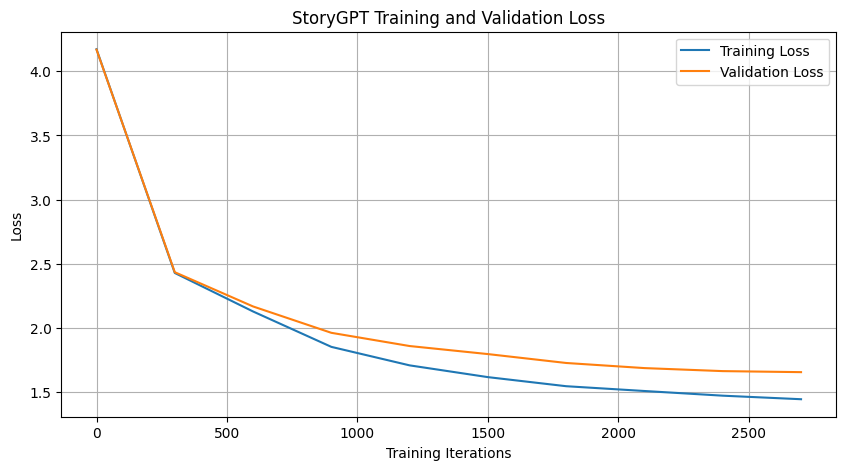

In [31]:
plt.figure(figsize=(10, 5))

steps = list(range(0, max_iters, eval_interval))

plt.plot(steps, train_losses, label="Training Loss")
plt.plot(steps, val_losses, label="Validation Loss")

plt.xlabel("Training Iterations")
plt.ylabel("Loss")
plt.title("StoryGPT Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [32]:
@torch.no_grad()
def generate_story(prompt, max_new_tokens=500, temperature=0.8):

    # Switch model to evaluation mode
    model.eval()

    # Convert prompt into token IDs
    context = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    # Generate characters one by one
    for _ in range(max_new_tokens):

        # Keep only the latest context
        idx_cond = context[:, -block_size:]

        # Get predictions
        logits, loss = model(idx_cond)

        # Select last character predictions
        logits = logits[:, -1, :]

        # Apply temperature
        logits = logits / temperature

        # Convert scores into probabilities
        probs = F.softmax(logits, dim=-1)

        # Sample next character
        next_token = torch.multinomial(
            probs,
            num_samples=1
        )

        # Append new character
        context = torch.cat(
            (context, next_token),
            dim=1
        )

    # Convert generated token IDs into text
    generated_text = decode(context[0].tolist())

    return generated_text

In [33]:
prompt = "Once upon a time"

story = generate_story(
    prompt,
    max_new_tokens=500,
    temperature=0.8
)

print("STORYGPT GENERATED STORY")
print("=" * 50)
print(story)

STORYGPT GENERATED STORY
Once upon a time be could out, sound so!

PAULINA:
For I am honour, I have no hear fair stand.

HENRY BOLINGBROKE:
Why, with the more fear his bestireign of the Plant plue.
What I dost thou sway hath a death
And father the bace of a heart a kand?

LADY ANNE:
Well, not my honest be the excutioneey,
Of thy father eyes to belieget.

COMINIUS:
Hears you short's gravess; but my libes faults.

VIRGILIIA:
I take no thy father: thou know the honour did,
As Cominius did your happen of thy sight!
Can my shept, and fir th


In [36]:
import torch

checkpoint = {
    "model_state_dict": model.state_dict(),

    # Save tokenizer
    "stoi": stoi,
    "itos": itos,
    "vocab_size": vocab_size,

    # Save architecture configuration
    "n_embd": n_embd,
    "n_head": n_head,
    "n_layer": n_layer,
    "block_size": block_size,
    "dropout": dropout,

    # Save training information
    "max_iters": max_iters,
    "learning_rate": learning_rate
}

torch.save(checkpoint, "storygpt_checkpoint.pth")

print("StoryGPT model saved successfully!")

StoryGPT model saved successfully!


In [37]:
from google.colab import files

files.download("storygpt_checkpoint.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import os

file_size = os.path.getsize("storygpt_checkpoint.pth")

print("Checkpoint exists:", os.path.exists("storygpt_checkpoint.pth"))
print("Checkpoint size:", round(file_size / (1024 * 1024), 2), "MB")

Checkpoint exists: True
Checkpoint size: 3.93 MB
